## Modeling our data with logistic regression

#### Split Data

In [11]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from implementations import *
from aux_cleaning_functions import *
from helpers import *
from aux_exploratory_data_analysis import *
from aux_preprocessing import *
from aux_grid_search import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


First, we lode our data: 

In [2]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("data")

In [3]:
# We transform the data form (-1,1) to (0,1) 
Y_tr = (y_train + 1) / 2

In [4]:
x_train, x_validation, x_te, y_train, y_validation, y_te = split_data(x_train, Y_tr, ratiotrain=0.7, ratiovalidation=0.15, seed=None)

Our first step is to evauate with the simplest model we know; linear regression (with mse as our loss). In this case since our data X is smaller than 10.000 when we tryed gradient descent we saw that it had a very high cost, therefore the grid search we will use is based on least squares; 

In [12]:
best_params, best_f1, results =  grid_search_logistic_regression_base(
    y_train, x_train,
    y_validation, x_validation,
    thershold_nans = [0.4, 0.3, 0.2],
    methods = ["undersample", "oversample"],
    thresholds=[0.3, 0.5, 0.7],
    max_iter=10000,
    gamma=0.05
)



=== Run 1/6 (method=undersample,thr_nans = 0.4) ===
Iter     0 | Loss = 0.684048 | Grad = 0.4303
Iter   100 | Loss = 0.510168 | Grad = 0.0776
Iter   200 | Loss = 0.493426 | Grad = 0.0442
Iter   300 | Loss = 0.486442 | Grad = 0.0319
Iter   400 | Loss = 0.482416 | Grad = 0.0253
Iter   500 | Loss = 0.479754 | Grad = 0.0211
Iter   600 | Loss = 0.477853 | Grad = 0.0181
Iter   700 | Loss = 0.476420 | Grad = 0.0159
Iter   800 | Loss = 0.475297 | Grad = 0.0142
Iter   900 | Loss = 0.474388 | Grad = 0.0128
Iter  1000 | Loss = 0.473634 | Grad = 0.0118
Iter  1100 | Loss = 0.472997 | Grad = 0.0109
Iter  1200 | Loss = 0.472450 | Grad = 0.0101
Iter  1300 | Loss = 0.471974 | Grad = 0.0094
Iter  1400 | Loss = 0.471556 | Grad = 0.0089
Iter  1500 | Loss = 0.471186 | Grad = 0.0084
Iter  1600 | Loss = 0.470857 | Grad = 0.0079
Iter  1700 | Loss = 0.470561 | Grad = 0.0075
Iter  1800 | Loss = 0.470294 | Grad = 0.0071
Iter  1900 | Loss = 0.470052 | Grad = 0.0068
Iter  2000 | Loss = 0.469831 | Grad = 0.0065
It

KeyboardInterrupt: 

-------- -> yet to identify. (the code takes a long time to run!! )

In [ ]:
best_threeshold_nans = ----
best_method = -----
best_threshold = -----

X_tr_base = x_train.copy()
y_tr_base = y_train.copy()
X_val_base = x_validation.copy()

keep_mask = remove_nan_feat(X_tr_base, threshold=best_threeshold_nans)
X_clean_nan_tr = X_tr_base[:, keep_mask]
X_clean_nan_val = X_val_base[:, keep_mask]

cat_mask, num_mask = detect_categorical_features(X_clean_nan_tr, max_unique=30)
X_imp_tr, medians_tr = impute_numerical(X_clean_nan_tr, num_mask, medians=None, means=None, strategy='medians')
X_imp_tr, modes_tr = impute_categorical(X_imp_tr, cat_mask, modes=None)

X_imp_val, _ = impute_numerical(X_clean_nan_val, num_mask, medians=medians_tr, strategy='medians')
X_imp_val, _ = impute_categorical(X_imp_val, cat_mask, modes=modes_tr)

X_std_tr, means_tr, stds_tr = standardize_features(X_imp_tr, num_mask, means=None, stds=None)
X_std_val, _, _ = standardize_features(X_imp_val, num_mask, means=means_tr, stds=stds_tr)

X_ohe_tr, categories = one_hot_encode(X_std_tr, cat_mask)   
X_ohe_val, _ = one_hot_encode(X_std_val, cat_mask, categories=categories)

corr_mask = feature_target_correlation(X_ohe_tr, y_tr_base, threshold_elimination=0.01)
X_corr_tr = X_ohe_tr[:, corr_mask]

colinear_mask = filter_colinear_features(X_corr_tr, y_tr_base, 0.9)
X_proc_tr = X_corr_tr[:, colinear_mask]
X_proc_val = X_ohe_val[:, corr_mask][:, colinear_mask]

X_tr_run, y_tr_run = balance_data(X_proc_tr.copy(), y_tr_base.copy(), method=best_method, random_state=None)                
w_final, final_loss = least_squares(y_tr_run, X_tr_run)

print("Final training loss:", final_loss)


KeyboardInterrupt: 

In [46]:
X_te_base = x_te.copy()
X_clean_nan_te = X_te_base[:, keep_mask]
X_imp_te, _ = impute_numerical(X_clean_nan_te, num_mask, medians=medians_tr, strategy='medians')
X_imp_te, _ = impute_categorical(X_imp_te, cat_mask, modes=modes_tr)
X_std_te, _, _ = standardize_features(X_imp_te, num_mask, means=means_tr, stds=stds_tr)
X_ohe_te, _ = one_hot_encode(X_std_te, cat_mask, categories=categories)
X_proc_te = X_ohe_te[:, corr_mask][:, colinear_mask]

acc, f1 = evaluate_model(y_te, X_proc_te, w_final, best_threshold)

 Accuracy: 91.14%
 F1 Score: 0.3234


Confusion Matrix:
[[43818  1149]
 [ 3212  1042]]
TN=43818, FP=1149, FN=3212, TP=1042


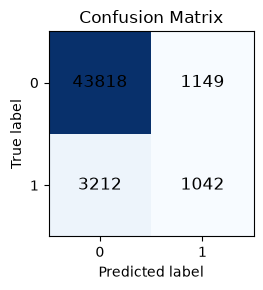

In [ ]:
preds, _ = predict_with_threshold(X_proc_te, w_final, threshold=best_threshold)
cm = confusion_matrix_numpy(y_te, preds)